# AI vs Real Image Detection - AIForensicNet V3 (Multi-Scale Static Bank + Anti-Compression)

Notebook ini melatih arsitektur **AIForensicNet V3**, model neural network forensik kustom generasi ke-3 yang memadukan kesederhanaan & ketangguhan V1 dengan inovasi multi-skala dan augmentasi anti-kompresi dunia nyata.

### 🌟 Inovasi & Peningkatan Utama pada AIForensicNet V3:
1. **Multi-Scale Static Forensic Filter Bank (12 Kanal)**: Menggabungkan 4 jenis filter statis deterministik (`requires_grad=False`):
   - **Laplacian 3x3 (3 kanal):** Menangkap derau frekuensi tinggi piksel mikro.
   - **Laplacian 5x5 (3 kanal):** Menangkap pola residual frekuensi menengah.
   - **Difference of Gaussians / DoG 5x5 (3 kanal):** Mendeteksi artefak penghalusan *de-noising* khas model Difusi (SD, Midjourney).
   - **Sobel Magnitude 3x3 (3 kanal):** Mendeteksi diskontinuitas gradien visual.
   Bebas dari ketidakstabilan gradient Bayar Conv dan stabil sejak epoch pertama.
2. **Balanced Dual-Stream Stem (50:50)**: 32 kanal forensik multi-skala + 32 kanal spasial RGB = 64 kanal fusi seimbang.
3. **No Over-Engineering**: Menghapus Spatial Attention dan DropPath dari V2 yang terbukti mengaburkan sinyal forensik dan menimbulkan bias tinggi ke Real.
4. **Global Mean + Standard Deviation Pooling (`MeanStdPool2d`)**: Mengukur rata-rata global dan variasi sebaran derau mikro di seluruh bidang spasial, kebal terhadap outlier/noise sporadis dibanding MaxPool.
5. **Anti-Compression & Robust Forensic Augmentation**: Dilengkapi simulasi `RandomJPEGCompression` (Quality 60–95) dan Gaussian blur mikro agar model kebal terhadap degradasi media sosial (WhatsApp, Instagram, WebP).
6. **Pelatihan Modern**: AMP FP16, Label Smoothing Cross-Entropy (0.05), Cosine Annealing LR dengan Linear Warmup, dan Test-Time Augmentation (TTA).


In [1]:
import warnings
warnings.filterwarnings('ignore', message='.*Palette images with Transparency.*')
warnings.filterwarnings('ignore', message='.*xFormers is not available.*')

import os
import copy
import time
import random
from io import BytesIO
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from tqdm.auto import tqdm
from datasets import load_dataset

from model_custom import AIForensicNetV3

# Inisialisasi Device Akselerasi (NVIDIA CUDA / CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('=' * 65)
if torch.cuda.is_available():
    print(f"Device Utama : {device} ({torch.cuda.get_device_name(0)})")
    print(f"Total VRAM   : {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
else:
    print(f"Device Utama : {device} (Peringatan: Gunakan GPU untuk pelatihan optimal)")
print('=' * 65)


Device Utama : cuda (NVIDIA GeForce RTX 4050 Laptop GPU)
Total VRAM   : 6.44 GB


In [2]:
# 1. Pemuatan Dataset Thunderbeast dari Cache Lokal / Hugging Face
DATASET_NAME = 'Thunderbeast/AI-Generated-vs-Real-Images-Datasets'
CACHE_DIR = './data'

print("Memuat dataset dari cache...")
dataset = load_dataset(
    DATASET_NAME,
    split='train',
    cache_dir=CACHE_DIR,
    verification_mode='no_checks'
)

# Pembagian Stratified 90% Training dan 10% Validasi
splits = dataset.train_test_split(test_size=0.10, stratify_by_column='label', seed=42)
train_hf = splits['train']
val_hf = splits['test']

print('=' * 65)
print(f"Total Sampel Dataset : {len(dataset):,} citra")
print(f"├─ Data Pelatihan (Train): {len(train_hf):,} citra (90%)")
print(f"└─ Data Validasi (Val)   : {len(val_hf):,} citra (10%)")
print('=' * 65)


Memuat dataset dari cache...


Total Sampel Dataset : 152,710 citra
├─ Data Pelatihan (Train): 137,439 citra (90%)
└─ Data Validasi (Val)   : 15,271 citra (10%)


In [3]:
# 2. Pipeline Augmentasi Anti-Kompresi & Robust Forensik

class RandomJPEGCompression:
    """
    Simulasi kompresi JPEG acak (Quality 60 - 95).
    Melatih model agar kebal terhadap degradasi kompresi media sosial (WhatsApp,
    Instagram, WebP, dsb.) dan tidak salah mengira artefak kompresi sebagai artefak AI.
    """
    def __init__(self, quality_range=(60, 95), p=0.45):
        self.quality_range = quality_range
        self.p = p

    def __call__(self, img):
        if random.random() < self.p:
            quality = random.randint(*self.quality_range)
            buf = BytesIO()
            img.save(buf, format='JPEG', quality=quality)
            buf.seek(0)
            return Image.open(buf).convert('RGB')
        return img


class HFToPyTorchDataset(Dataset):
    """Adapter untuk menghubungkan Hugging Face Dataset dengan PyTorch DataLoader."""
    def __init__(self, hf_dataset, transform=None):
        self.dataset = hf_dataset
        self.transform = transform

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        item = self.dataset[idx]
        image = item["image"]
        label = item["label"]

        if image.mode == 'P' and 'transparency' in image.info:
            image = image.convert('RGBA')
        if image.mode != "RGB":
            image = image.convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, label


# Transformasi Pelatihan & Validasi
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    RandomJPEGCompression(quality_range=(60, 95), p=0.45),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.RandomApply([
        transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 0.5))
    ], p=0.20),
    transforms.ColorJitter(brightness=0.08, contrast=0.08, saturation=0.08),
    transforms.RandomResizedCrop((224, 224), scale=(0.92, 1.0), ratio=(0.95, 1.05)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

val_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

train_ds = HFToPyTorchDataset(train_hf, transform=train_transforms)
val_ds = HFToPyTorchDataset(val_hf, transform=val_transforms)

BATCH_SIZE = 32
use_pin = torch.cuda.is_available()

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=use_pin)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=use_pin)

print("✅ Pipeline Augmentasi Anti-Kompresi & DataLoader Berhasil Dikonfigurasi.")


✅ Pipeline Augmentasi Anti-Kompresi & DataLoader Berhasil Dikonfigurasi.


In [4]:
# 3. Inisialisasi Model AIForensicNet V3
model = AIForensicNetV3(num_classes=2, dropout_p=0.25).to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print('=' * 65)
print('🧠 ARSITEKTUR AIForensicNet V3 (From Scratch):')
print(f'├─ Total Parameter    : {total_params:,} (~{total_params/1e6:.2f}M)')
print(f'└─ Trainable Parameter: {trainable_params:,} (~{trainable_params/1e6:.2f}M)')
print('=' * 65)

# Verifikasi Forward Pass
dummy_x = torch.randn(2, 3, 224, 224, device=device)
with torch.no_grad():
    dummy_out = model(dummy_x)
print(f"Uji Forward Pass Sukses: Tensor Input {tuple(dummy_x.shape)} -> Output {tuple(dummy_out.shape)}")


🧠 ARSITEKTUR AIForensicNet V3 (From Scratch):
├─ Total Parameter    : 3,067,874 (~3.07M)
└─ Trainable Parameter: 3,067,874 (~3.07M)
Uji Forward Pass Sukses: Tensor Input (2, 3, 224, 224) -> Output (2, 2)


In [5]:
# 4. Pengaturan Hyperparameter & Optimizer
EPOCHS = 15
LEARNING_RATE = 5e-4
WEIGHT_DECAY = 1e-2
LABEL_SMOOTHING = 0.05
MODEL_SAVE_PATH = 'best_aiforensicnet_v3_ai_vs_real.pth'

# Loss Function dengan Label Smoothing untuk mencegah over-confidence
criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
eval_criterion = nn.CrossEntropyLoss()

# Optimizer AdamW
optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

# Learning Rate Scheduler: Warmup 2 Epoch + Cosine Annealing
warmup_epochs = 2
cosine_epochs = EPOCHS - warmup_epochs

def lr_lambda(epoch):
    if epoch < warmup_epochs:
        return float(epoch + 1) / float(max(1, warmup_epochs))
    else:
        progress = float(epoch - warmup_epochs) / float(max(1, cosine_epochs))
        return max(1e-3, 0.5 * (1.0 + np.cos(np.pi * progress)))

scheduler = optim.lr_scheduler.LambdaLR(optimizer, lr_lambda=lr_lambda)

# Automatic Mixed Precision (AMP FP16)
scaler = torch.amp.GradScaler('cuda', enabled=torch.cuda.is_available())

print("✅ Konfigurasi Optimizer, Scheduler, dan AMP FP16 Siap.")


✅ Konfigurasi Optimizer, Scheduler, dan AMP FP16 Siap.


In [6]:
# 5. Eksekusi Loop Pelatihan & Validasi
best_val_acc = 0.0
best_val_f1 = 0.0
best_model_wts = copy.deepcopy(model.state_dict())

history = {
    'train_loss': [], 'train_acc': [],
    'val_loss': [], 'val_acc': [], 'val_f1': []
}

print(f"Mulai pelatihan AIForensicNet V3 ({EPOCHS} Epoch, AMP FP16, Multi-Scale Filter Bank)...\n" + '='*65)

for epoch in range(EPOCHS):
    start_time = time.time()
    current_lr = optimizer.param_groups[0]['lr']

    # ---------------- FASE TRAINING ----------------
    model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0

    train_bar = tqdm(train_loader, desc=f"Epoch [{epoch+1:02d}/{EPOCHS}] Train (LR: {current_lr:.1e})", leave=True)
    optimizer.zero_grad(set_to_none=True)

    for images, labels in train_bar:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with torch.amp.autocast('cuda', enabled=torch.cuda.is_available()):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()
        optimizer.zero_grad(set_to_none=True)

        train_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        train_correct += torch.sum(preds == labels).item()
        train_total += images.size(0)

        train_bar.set_postfix({
            'loss': f"{loss.item():.4f}",
            'acc': f"{(train_correct / train_total) * 100:.2f}%"
        })

    scheduler.step()
    epoch_train_loss = train_loss / train_total
    epoch_train_acc = train_correct / train_total

    # ---------------- FASE VALIDASI ----------------
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0
    all_val_preds = []
    all_val_labels = []

    val_bar = tqdm(val_loader, desc=f"Epoch [{epoch+1:02d}/{EPOCHS}] Val  ", leave=True)

    with torch.no_grad():
        for images, labels in val_bar:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.amp.autocast('cuda', enabled=torch.cuda.is_available()):
                outputs = model(images)
                loss = eval_criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += torch.sum(preds == labels).item()
            val_total += images.size(0)

            all_val_preds.extend(preds.cpu().numpy())
            all_val_labels.extend(labels.cpu().numpy())

            val_bar.set_postfix({
                'val_loss': f"{loss.item():.4f}",
                'val_acc': f"{(val_correct / val_total) * 100:.2f}%"
            })

    epoch_val_loss = val_loss / val_total
    epoch_val_acc = val_correct / val_total
    epoch_val_f1 = f1_score(all_val_labels, all_val_preds, average='macro')
    elapsed_sec = time.time() - start_time

    history['train_loss'].append(epoch_train_loss)
    history['train_acc'].append(epoch_train_acc)
    history['val_loss'].append(epoch_val_loss)
    history['val_acc'].append(epoch_val_acc)
    history['val_f1'].append(epoch_val_f1)

    print(f"📊 Ringkasan Epoch {epoch+1:02d}:")
    print(f"   Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc * 100:.2f}%")
    print(f"   Val Loss  : {epoch_val_loss:.4f} | Val Acc  : {epoch_val_acc * 100:.2f}% | Val Macro F1: {epoch_val_f1:.4f}")
    print(f"   Durasi    : {elapsed_sec / 60:.2f} menit")

    # Checkpoint Otomatis berdasarkan Akurasi Validasi Tertinggi
    if epoch_val_acc > best_val_acc:
        best_val_acc = epoch_val_acc
        best_val_f1 = epoch_val_f1
        best_model_wts = copy.deepcopy(model.state_dict())
        torch.save(best_model_wts, MODEL_SAVE_PATH)
        print(f"   🌟 CHECKPOINT TERBAIK DIPERBARUI! Disimpan ke: '{MODEL_SAVE_PATH}'")

    print('-' * 65)

print('\nPelatihan Selesai!')
print(f'Akurasi Validasi Tertinggi: {best_val_acc * 100:.2f}% (F1-Macro: {best_val_f1:.4f})')


Mulai pelatihan AIForensicNet V3 (15 Epoch, AMP FP16, Multi-Scale Filter Bank)...


Epoch [01/15] Train (LR: 2.5e-04):   0%|          | 0/4295 [00:00<?, ?it/s]

KeyboardInterrupt: 

ValueError: x and y must have same first dimension, but have shapes (15,) and (0,)

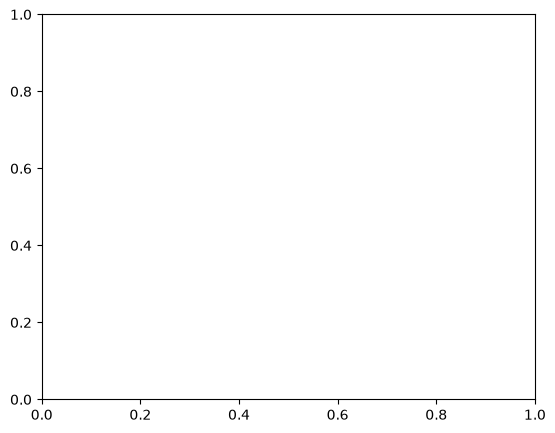

In [ ]:
# 6. Visualisasi Kurva Loss dan Akurasi
plt.figure(figsize=(14, 5))

# Plot Loss
plt.subplot(1, 2, 1)
plt.plot(range(1, EPOCHS + 1), history['train_loss'], 'b-o', label='Train Loss', linewidth=2)
plt.plot(range(1, EPOCHS + 1), history['val_loss'], 'r-s', label='Validation Loss', linewidth=2)
plt.title('Kurva Loss per Epoch (AIForensicNet V3)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# Plot Akurasi
plt.subplot(1, 2, 2)
plt.plot(range(1, EPOCHS + 1), [x * 100 for x in history['train_acc']], 'b-o', label='Train Acc', linewidth=2)
plt.plot(range(1, EPOCHS + 1), [x * 100 for x in history['val_acc']], 'g-^', label='Validation Acc', linewidth=2)
plt.title('Kurva Akurasi per Epoch (AIForensicNet V3)')
plt.xlabel('Epoch')
plt.ylabel('Akurasi (%)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


In [ ]:
# 7. Evaluasi Mendalam pada Seluruh Data Validasi (Standard vs Test-Time Augmentation)
model.load_state_dict(best_model_wts)
model.eval()

y_true = []
y_pred_std = []
y_pred_tta = []

with torch.no_grad():
    for images, labels in tqdm(val_loader, desc='Evaluasi Final Validation'):
        images = images.to(device)
        images_flip = torch.flip(images, dims=[3])

        with torch.amp.autocast('cuda', enabled=torch.cuda.is_available()):
            out_std = model(images)
            out_flip = model(images_flip)

        p_std = torch.softmax(out_std, dim=1)
        p_flip = torch.softmax(out_flip, dim=1)
        p_tta = (p_std + p_flip) / 2.0

        _, pred_std = torch.max(p_std, 1)
        _, pred_tta = torch.max(p_tta, 1)

        y_true.extend(labels.numpy())
        y_pred_std.extend(pred_std.cpu().numpy())
        y_pred_tta.extend(pred_tta.cpu().numpy())

target_names = ['AI-Generated (0)', 'Real Image (1)']

acc_std = np.mean(np.array(y_pred_std) == np.array(y_true)) * 100.0
acc_tta = np.mean(np.array(y_pred_tta) == np.array(y_true)) * 100.0

print('=' * 65)
print(f"🎯 AKURASI VALIDASI STANDAR : {acc_std:.2f}%")
print(f"🚀 AKURASI VALIDASI TTA     : {acc_tta:.2f}% (Peningkatan: {acc_tta - acc_std:+.2f}%)")
print('=' * 65)

print('\nCLASSIFICATION REPORT (AIForensicNet V3 + TTA):')
print(classification_report(y_true, y_pred_tta, target_names=target_names, digits=4))

# Visualisasi Confusion Matrix
cm = confusion_matrix(y_true, y_pred_tta)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=target_names)
fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(cmap='Blues', ax=ax, values_format='d')
plt.title('Confusion Matrix AIForensicNet V3 (TTA Mode)')
plt.show()


In [ ]:
# 8. Fungsi Pengujian Prediksi Citra Tunggal dengan TTA
def predict_image(image_path, model, device):
    """
    Menguji citra tunggal dan mengembalikan prediksi label serta probabilitas kepercayaan
    menggunakan Test-Time Augmentation (TTA).
    """
    if not os.path.exists(image_path):
        print(f"[ERROR] File gambar tidak ditemukan: {image_path}")
        return

    image = Image.open(image_path)
    if image.mode == 'P' and 'transparency' in image.info:
        image = image.convert('RGBA')
    if image.mode != "RGB":
        image = image.convert("RGB")

    tensor_img = val_transforms(image).unsqueeze(0).to(device)
    tensor_img_flip = torch.flip(tensor_img, dims=[3])

    with torch.no_grad():
        out_orig = model(tensor_img)
        out_flip = model(tensor_img_flip)
        prob_orig = torch.softmax(out_orig, dim=1)[0]
        prob_flip = torch.softmax(out_flip, dim=1)[0]
        probs = (prob_orig + prob_flip) / 2.0

        confidence, predicted_class = torch.max(probs, 0)

    label_map = {0: 'AI-Generated Image 🤖', 1: 'Real Image 🖼️'}
    predicted_label = label_map[predicted_class.item()]
    conf_pct = confidence.item() * 100.0

    print('=' * 50)
    print(f"File Uji          : {os.path.basename(image_path)}")
    print(f"Hasil Prediksi    : {predicted_label}")
    print(f"Tingkat Keyakinan : {conf_pct:.2f}%")
    print(f"P(AI-Generated)   : {probs[0].item() * 100.0:.2f}%")
    print(f"P(Real Image)     : {probs[1].item() * 100.0:.2f}%")
    print('=' * 50)

# Contoh pengujian citra contoh
for sample in ['real.jpg', 'images (2).jpg', 'makan.jpeg', 'gani.jpeg', 'test1.webp', 'wa.jpeg']:
    if os.path.exists(sample):
        predict_image(sample, model, device)
